In [19]:
import pandas as pd
import os
import cv2
import torch
import torchvision
import torch.nn.functional as functional
from torch.utils.data import DataLoader, TensorDataset, Dataset,  WeightedRandomSampler
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
from torchvision import models

In [20]:
# def preprocess_image(image_path, transform=None):
#     image = cv2.imread(image_path)
#     image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
#     image = cv2.resize(image, (224, 224))
#     image = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])(transforms.ToTensor()(image))
#     image = image.unsqueeze(0)
#     return image

In [21]:
# model.fc

In [22]:
# def get_class_label(preds):
#     _, class_index = torch.max(preds, 1)
#     return class_index.item()

In [23]:
# def get_target_layer(model,target_layer_name):
#     for name, layer in model.named_modules():
#         if name == target_layer_name:
#             return layer
#     raise ValueError(f"Layer '{target_layer_name}'not found in the model.")

In [24]:
# #function to generate Grad-CAM heatmap
# def compute_gradcam(model, imag_tensor,  class_index,target_layer_name ="layer4[1].conv2"):
#     target_layer = get_target_layer(model,target_layer_name)


#     #forward hook to store activations
#     activations = None
#     def forward_hook(module, input, output):
#         nonlocal activations
#         activations=output

#     hook = target_layer.register_forwrad_hook(forward_hook)



#     #compute gradients
#     img_tensor.requires_grad_(True)
#     preds = model(img_tensor)
#     loss = preds[:,class_index]
#     model.zero_grad()
#     loss.backward()

#     #get gradients
#     grads = img_tensor.grad.cpu().numpy()
#     pooled_grads = np.mean(grads,axis=(0,2,3))


#     #remove the hook
#     hook.remove()


    # activations = activations.detach().cpu().numpy()[0]
    # for i in range(pooled_grads.shape[0]):
    #     activations[i,...]*= pooled_grads[i]

    # heatmap = np.mean(activations, axis=0)
    # heatmap = np.maximum(heatmap,0)
    # heatmap /= np.max(heatmap)
    

    # return heatmap





    


In [25]:
# # Overlay heatmap on image
# def overlay_heatmap(img_path, heatmap, alpha=0.4):
#     img = cv2.imread(img_path, cv2.IMREAD_COLOR)
#     heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
#     heatmap = np.uint8(255 * heatmap)
#     heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

#     superimposed_img = cv2.addWeighted(img, alpha, heatmap, 1 - alpha, 0)
#     return superimposed_img

# if __name__ == "__main__":
#     # Load a pretrained model 
#     model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
#     model.eval()

#     # Example Usage
#     img_path = "/home/dbtproject/barsha/Image/test_set/Class0_Graminicola/Chaibasa_1.tiff"  # Replace with your image path
#     img_tensor = preprocess_image(img_path)

#     # Get model predictions
#     with torch.no_grad():
#         preds = model(img_tensor)
#     class_index = get_class_label(preds)

#     print(f"Predicted Class Index: {class_index}")

#     # Compute Grad-CAM heatmap
#     heatmap = compute_gradcam(model, img_tensor, class_index)

#     # Overlay heatmap on the original image
#     output_img = overlay_heatmap(img_path, heatmap)

#     # 
    

In [26]:
# model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
# model
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, 3)
model.load_state_dict(torch.load("resnet50_nematode_weights.pth"))
target_layers = model.layer4[-1].conv3
model.eval()
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [27]:
# model.eval()
# target_layer = model.layer4[-1].conv3

In [28]:
img_path = '/home/dbtproject/barsha/Image/test_set/Class0_Graminicola/Chaibasa_1.tiff'

img = Image.open(img_path).convert('RGB')      #oopen image using PIL library
img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


In [29]:
input_tensor = img_transform(img).unsqueeze(0)
print(input_tensor)

tensor([[[[-1.3473, -1.3473, -1.3473,  ..., -1.2959, -1.2788, -1.2617],
          [-1.3473, -1.3473, -1.3302,  ..., -1.2959, -1.2788, -1.2617],
          [-1.3473, -1.3473, -1.3302,  ..., -1.2788, -1.2788, -1.2617],
          ...,
          [-1.3473, -1.3473, -1.3302,  ..., -1.2617, -1.2788, -1.2788],
          [-1.3302, -1.3302, -1.3302,  ..., -1.2788, -1.2788, -1.2788],
          [-1.3302, -1.3302, -1.3302,  ..., -1.2788, -1.2788, -1.2788]],

         [[-1.2479, -1.2479, -1.2479,  ..., -1.1954, -1.1779, -1.1604],
          [-1.2479, -1.2479, -1.2304,  ..., -1.1954, -1.1779, -1.1604],
          [-1.2479, -1.2479, -1.2304,  ..., -1.1779, -1.1779, -1.1604],
          ...,
          [-1.2479, -1.2479, -1.2304,  ..., -1.1604, -1.1779, -1.1779],
          [-1.2304, -1.2304, -1.2304,  ..., -1.1779, -1.1779, -1.1779],
          [-1.2304, -1.2304, -1.2304,  ..., -1.1779, -1.1779, -1.1779]],

         [[-1.0201, -1.0201, -1.0201,  ..., -0.9678, -0.9504, -0.9330],
          [-1.0201, -1.0201, -

In [30]:
print(input_tensor.shape)

torch.Size([1, 3, 224, 224])


In [31]:
#hook to capture activations and gradients

activations=[]
gradients=[]

def forward_hook(module,input,output):
    activations.append(output)

def backward_hook(module,grad_in,grad_out):
    gradients.append(grad_out[0])

target_layers.register_forward_hook(forward_hook)
target_layers.register_full_backward_hook(backward_hook)

#forward pass
fp = model(input_tensor) 
output = fp
print('---------')
print(fp.shape)
pred_class = output.argmax(dim=1)
print(pred_class)
print(output[0,pred_class])

#backward pass
model.zero_grad()
output[0,pred_class].backward()
print()


act = activations[0].squeeze().detach()
grad = gradients[0].squeeze().detach()
print(act.shape, '\n', grad.shape)


---------
torch.Size([1, 3])
tensor([0])
tensor([1.0798], grad_fn=<IndexBackward0>)

torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


In [32]:
#global avg pooling
weights = grad.mean(dim=(1,2))
cam = torch.zeros(act.shape[1:], dtype = torch.float32)
print(weights.shape)
print(cam.shape)

torch.Size([2048])
torch.Size([7, 7])


In [33]:
for i, w in enumerate(weights):
    cam += w*act[i]

cam = functional.relu(cam)
cam = cam-cam.min()
cam = cam/cam.max()

cam = cam.numpy()

In [34]:
threshold = 0.4
binary_mask = (cam>threshold).astype('uint8')
mask_resized = cv2.resize(binary_mask, (224, 224))

# inverted_mask = (1-binary_mask)*255
# inverted_mask = cv2.resize(inverted_mask,(224,224))
# inverted_mask_rgb = cv2.cvtColor(inverted_mask, cv2.COLOR_GRAY2RGB)

# bw_mask = np.ones((224, 224), dtype=np.uint8) * 255  # start with white background
# bw_mask[mask_resized == 1] = 0 
# bw_mask_rgb = cv2.cvtColor(bw_mask, cv2.COLOR_GRAY2RGB)


In [35]:
#resize and overlay on image

heatmap = cv2.resize(cam,(224,224))
heatmap = cv2.applyColorMap(np.uint8(255*heatmap), cv2.COLORMAP_JET)
img_np = np.array(img.resize((224,224)))
overlay = cv2.addWeighted(img_np,0.5,heatmap, 0.5, 0)



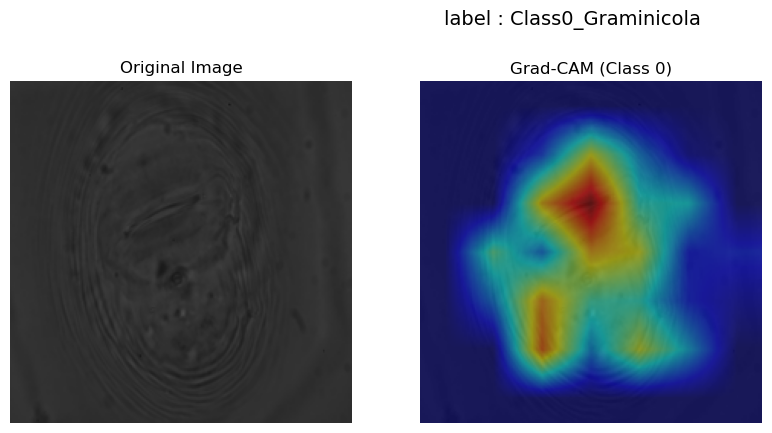

In [36]:

# BGR → RGB
overlay_rgb = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)

#apply mask on original image
# segmented_img = img_np.copy()
# segmented_img[mask_resized==0] = 0
true_label = os.path.basename(os.path.dirname(img_path))

# -------------------------
# Plot: Original vs Grad-CAM
# -------------------------
plt.figure(figsize=(15,5))

plt.subplot(1, 3, 1)
plt.imshow(img_np)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(overlay_rgb)
plt.title(f"Grad-CAM (Class {pred_class.item()})")
plt.axis("off")

# plt.subplot(1,3,3)
# plt.imshow(bw_mask, cmap = 'gray' )
# plt.title('Grad-CAM masked region')
# plt.axis('off')

plt.suptitle(f'label : {true_label}', fontsize =14)


plt.show()





